# 04 · Siting new rapid hubs under budget, capacity, grid and demand uncertainty

**Question.** With a given budget, where should the next 4 × 150 kW hubs go so that the most currently unmet or queue-constrained rapid demand is served within 8 minutes' drive — and which choices stay good if demand is 30 % lower or higher?

**Method.** Candidates = plausible hexes (parking / fuel / retail present or heavy traffic, primary substation not RED), pre-filtered to the 500 with most local unmet demand. Capacitated maximal covering MILP (HiGHS via scipy) with per-hub capacity from Erlang C (P(wait) ≤ 15 % at peak) and a budget; robust two-stage version over P10/P50/P90 scenarios; greedy uncapacitated baseline for contrast.

In [1]:
import warnings, json
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from chargescape.utils.paths import PROCESSED, INTERIM, FIGURES, TABLES, DOCS
from chargescape.utils.io import read_gdf
from chargescape.viz.figures import hex_map, save, barh, boroughs
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 40)
feats = read_gdf(PROCESSED / "hex_features_r8.small.parquet")
print(feats.shape)

(2374, 81)


In [2]:
meta = json.loads((TABLES / "siting_meta_2026.json").read_text()); print(meta)
sweep = pd.read_csv(TABLES / "siting_budget_sweep_2026.csv")
cap = meta["hub_capacity_sessions_day"]
sweep["capacity_bound_share"] = sweep["covered_p50"] / (sweep["n_hubs"] * cap)  # 1.0 = every hub is full
sweep["hubs_needed_for_all_unmet"] = np.ceil(sweep["total_unmet_p50"] / cap).astype(int)
sweep.round(3)

{'method': 'osm_igraph', 'scenario': '2026', 'n_candidates': 500, 'hub_capacity_sessions_day': 33.31170119357964, 'radius_min': 8.0, 'hub_cost_gbp': 390000}


,budget_m,n_hubs,covered_p50,total_unmet_p50,coverage_share,greedy_uncapacitated_covered,status,robust_n_hubs,robust_overlap_with_p50,robust_status,capacity_bound_share,hubs_needed_for_all_unmet
0,5.0,12,399.740,2936.299,0.136,2114.980,Optimal,12,3,Optimal,1.000,89
1,10.0,25,832.793,2936.299,0.284,2538.882,Optimal,25,3,Time limit reached. (HiGHS Status 13: Time lim...,1.000,89
2,20.0,51,1698.897,2936.299,0.579,2603.784,Optimal,51,11,Time limit reached. (HiGHS Status 13: Time lim...,1.000,89
3,40.0,101,2570.078,2936.299,0.875,2603.784,Optimal,96,35,Time limit reached. (HiGHS Status 13: Time lim...,0.764,89


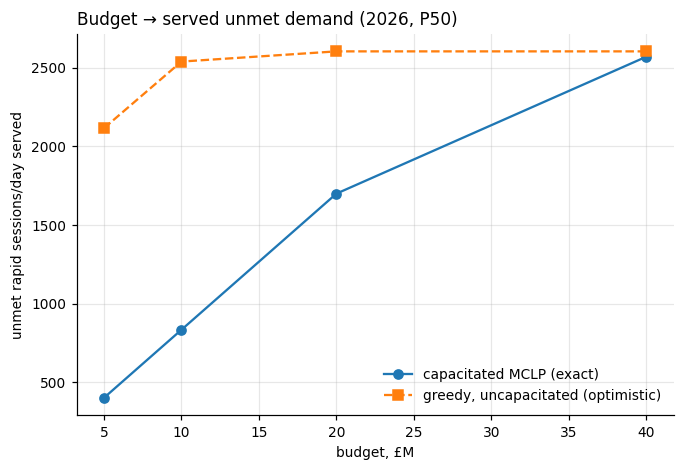

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sweep.budget_m, sweep.covered_p50, "o-", label="capacitated MCLP (exact)")
ax.plot(sweep.budget_m, sweep.greedy_uncapacitated_covered, "s--", label="greedy, uncapacitated (optimistic)")
ax.set_xlabel("budget, £M"); ax.set_ylabel("unmet rapid sessions/day served"); ax.set_title("Budget → served unmet demand (2026, P50)", loc="left"); ax.legend(frameon=False); ax.grid(alpha=0.3)
save(fig, "04_budget_curve.png"); plt.show()

## Selected hubs (P50 vs robust) at £20M

budget £20M: 51 hubs (P50), 51 hubs (robust), 11 in both


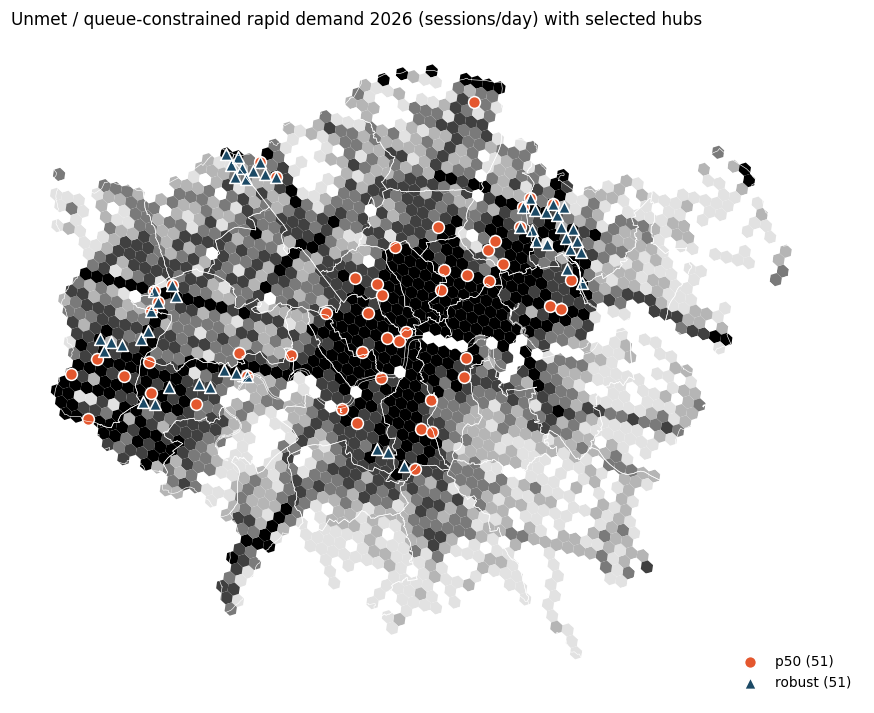

model,p50,robust
borough,,
Westminster,6,0
Waltham Forest,5,2
Hillingdon,5,7
Ealing,4,4
Hackney,4,0
Hounslow,4,8
Lambeth,4,1
Newham,3,1
Camden,3,0


In [4]:
sel = pd.read_parquet(PROCESSED / "siting_selected_2026.small.parquet")
b = 20.0 if (sel.budget_m == 20.0).any() else sel.budget_m.max()
s20 = sel[sel.budget_m == b]
both = set(s20[s20.model == "p50"].h3) & set(s20[s20.model == "robust"].h3)
print(f"budget £{b:.0f}M: {len(s20[s20.model=='p50'])} hubs (P50), {len(s20[s20.model=='robust'])} hubs (robust), {len(both)} in both")
svc = pd.read_parquet(PROCESSED / "hex_service_2026.small.parquet")
g = feats.merge(svc, on="h3", how="left")
g["unmet"] = g["unserved_sessions_day"].fillna(0) + g["rapid_sessions_day"].fillna(0) * g["served_share"].fillna(0) * np.clip(g["expected_wait_min"].fillna(0) / 30, 0, 1)
fig, ax = plt.subplots(figsize=(10, 8))
hex_map(g, "unmet", "Unmet / queue-constrained rapid demand 2026 (sessions/day) with selected hubs", cmap="Greys", scheme="quantiles", k=6, ax=ax, legend_label="sessions/day")
hexes = feats.set_index("h3")
for model, color, marker in [("p50", "#e4572e", "o"), ("robust", "#1b4965", "^")]:
    pts = hexes.loc[s20[s20.model == model].h3]
    gpd.GeoDataFrame(pts, geometry=gpd.points_from_xy(pts.lon, pts.lat), crs=4326).to_crs(27700).plot(ax=ax, color=color, marker=marker, markersize=60, label=f"{model} ({len(pts)})", edgecolor="white")
ax.legend(loc="lower right", frameon=False); save(fig, "04_selected_hubs.png"); plt.show()
s20.groupby(["model", "borough"]).size().unstack(0).fillna(0).astype(int).sort_values("p50", ascending=False).head(15)

## Reading
* **The regime is capacity-bound, not location-bound.** With a 15 % peak-wait service level a 4 × 150 kW hub absorbs about 33 sessions/day, so covered demand rises almost linearly with budget (`capacity_bound_share` ≈ 1) until the ~90 hubs needed to absorb today's unmet demand. The exact model therefore serves a fraction of what the greedy uncapacitated estimate claims — that gap is demand a hub physically cannot take at an acceptable wait, which naïve coverage models hand out for free.
* **Low overlap between the P50 and robust solutions is degeneracy, not fragility.** When every hub fills up, many candidate sets are near-equivalent; the robust model simply picks another equivalent set. The operationally useful reading is the *set of hexes that appear in either* solution — the demand-dense corridors where hubs pay back under any scenario — and the phasing question becomes "how many hubs per corridor", which the queue model answers.
* Every selected hex carries its primary-substation headroom label, so a RED site never enters the candidate set and loaded primaries pay a connection uplift.
* Relaxing the service level (e.g. P(wait) ≤ 30 %) or larger hubs (8 ports) raise per-hub capacity and shift the regime back towards location choice — a one-line change in `siting_pipeline.py` to explore.